# Polymarket EDA

## Preamble

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import sqlite3

## Load data

In [3]:
# Open the database
#con = sqlite3.connect("../polymarket-scraper/events.db")

from google.colab import drive
drive.mount('/content/drive')


db_path = "/content/drive/MyDrive/Colab Notebooks/class-project-neon/polymarket-scraper/events.db"

con = sqlite3.connect(db_path)
#df = pd.read_sql("SELECT * FROM events", con)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Read SQL db into DataFrame
df = pd.read_sql("SELECT * FROM events",con)

## Clean Data

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297373 entries, 0 to 297372
Data columns (total 88 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     297373 non-null  object 
 1   ticker                 297371 non-null  object 
 2   slug                   297373 non-null  object 
 3   title                  297373 non-null  object 
 4   description            296691 non-null  object 
 5   resolutionSource       281430 non-null  object 
 6   startDate              297348 non-null  object 
 7   creationDate           297282 non-null  object 
 8   endDate                297172 non-null  object 
 9   image                  297373 non-null  object 
 10  icon                   297373 non-null  object 
 11  active                 297373 non-null  int64  
 12  closed                 297373 non-null  int64  
 13  archived               297365 non-null  float64
 14  new                    297335 non-nu

In [6]:
# Set the correct type for boolean columns
boolean_columns = (
    "active",
    "closed",
    "archived",
    "new",
    "featured",
    "restricted",
    "commentsEnabled",
    "enableOrderBook",
    "negRisk",
    "cyom",
    "showAllOutcomes",
    "showMarketImages",
    "automaticallyResolved",
    "enableNegRisk",
    "automaticallyActive",
    "live",
    "ended",
    "estimateValue",
    "cantEstimate",
    "pendingDeployment",
    "deploying"
)

df[[*boolean_columns]] = df[[*boolean_columns]].astype('boolean')

In [7]:
# Parse the string JSON values
object_columns = (
    "markets",
    "tags",
    "eventCreators",
)

In [8]:
def parse_json(json_str : str) :
    return json.loads(json_str) if isinstance(json_str,str) else np.nan

df[[*object_columns]] = df[[*object_columns]].map(parse_json)

In [9]:
df[[*object_columns]]

,markets,tags,eventCreators
0,"[{'id': '239826', 'question': 'NBA: Will the M...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
1,"[{'id': '239167', 'question': 'NFL: Will the F...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
2,"[{'id': '238885', 'question': '(In-Game Tradin...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
3,"[{'id': '245948', 'question': '2022 Norway Che...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
4,"[{'id': '239496', 'question': 'NBA: Will the H...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
...,...,...,...
297368,"[{'id': '255435', 'question': 'Trump $83.3m ve...","[{'id': '164', 'label': 'law', 'slug': 'law', ...",NaN
297369,"[{'id': '255440', 'question': 'Boeing whistleb...","[{'id': '846', 'label': 'Boeing', 'slug': 'boe...",NaN
297370,"[{'id': '255443', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN
297371,"[{'id': '255447', 'question': 'Will Arizona be...","[{'id': '100215', 'label': 'All', 'slug': 'all...",NaN


## Preliminary Analysis

### General statistics for interesting numerical columns

In [10]:
interesting_columns = (
    "liquidity",
    "volume",
    "openInterest",
    "volume24hr",
    "volume1wk",
    "volume1mo",
    "volume1yr",
    "commentCount",
)

In [11]:
#Basic EDA
print("Shape: ", df.shape)
print("\n")
print(df.dtypes.value_counts())
print("\n")
print(df.isnull().mean().sort_values(ascending=False).head(15))
print("\n")

proper_list = df[df['volume']>0]
print("Usable Columns: ", len(proper_list.columns))
print("\n")

df[list(interesting_columns)].describe()

Shape:  (297373, 88)


object     45
boolean    21
float64    20
int64       2
Name: count, dtype: int64


carouselMap           0.999987
color                 0.999926
gameStatus            0.999923
estimatedValue        0.999909
disqusThread          0.999906
sportsradarMatchId    0.999842
cantEstimate          0.999828
subcategory           0.999771
turnProviderId        0.999748
spreadsMainLine       0.999667
totalsMainLine        0.999667
eventCreators         0.999546
createdBy             0.999388
tweetCount            0.999213
electionType          0.998739
dtype: float64


Usable Columns:  88




,liquidity,volume,openInterest,volume24hr,volume1wk,volume1mo,volume1yr,commentCount
count,1.304370e+05,1.912240e+05,2.856820e+05,1.170200e+04,1.250270e+05,1.250910e+05,1.250970e+05,296451.000000
mean,3.958335e+03,3.122899e+05,2.067710e+03,2.805297e+04,2.002742e+05,2.521287e+05,3.213485e+05,280.564451
std,2.323964e+05,1.159353e+07,1.419866e+05,4.790150e+05,2.116753e+06,3.627355e+06,6.806639e+06,1524.208972
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-61.000000
25%,0.000000e+00,3.893334e+03,0.000000e+00,0.000000e+00,2.701823e+03,2.952487e+03,3.053414e+03,0.000000
50%,0.000000e+00,1.749002e+04,0.000000e+00,3.320500e+01,2.080678e+04,2.186439e+04,2.250848e+04,0.000000
75%,0.000000e+00,7.591977e+04,0.000000e+00,2.912266e+03,9.267189e+04,9.677674e+04,9.928892e+04,0.000000
max,4.788689e+07,3.686335e+09,5.266949e+07,4.574479e+07,4.291211e+08,5.816272e+08,9.992162e+08,142928.000000


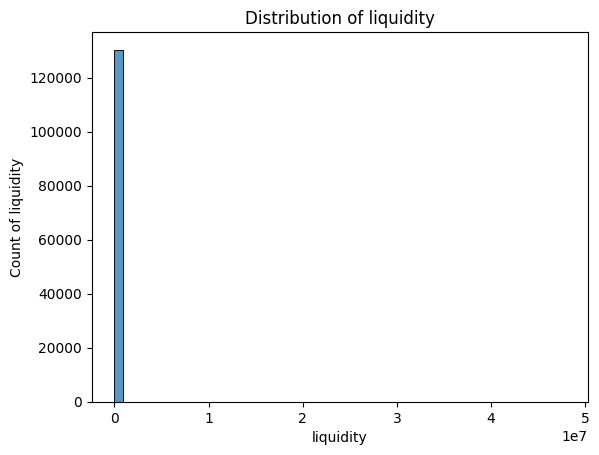

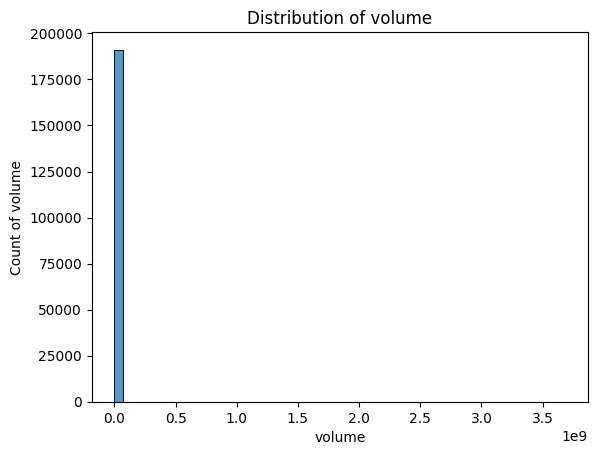

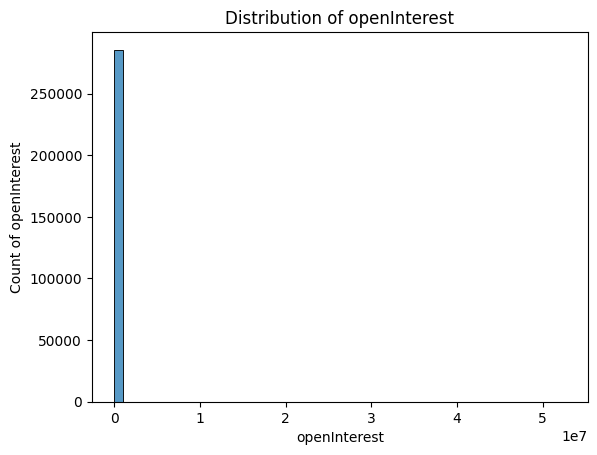

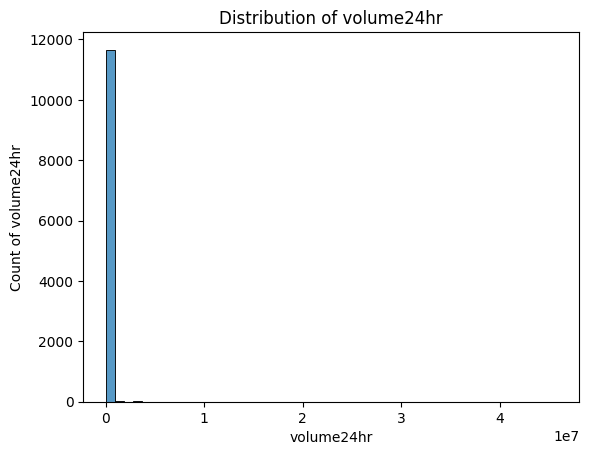

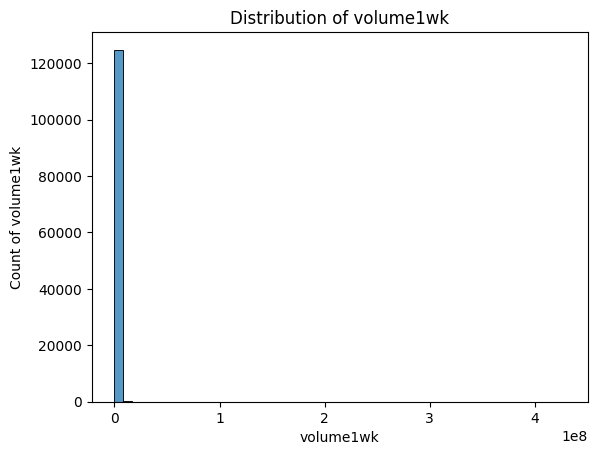

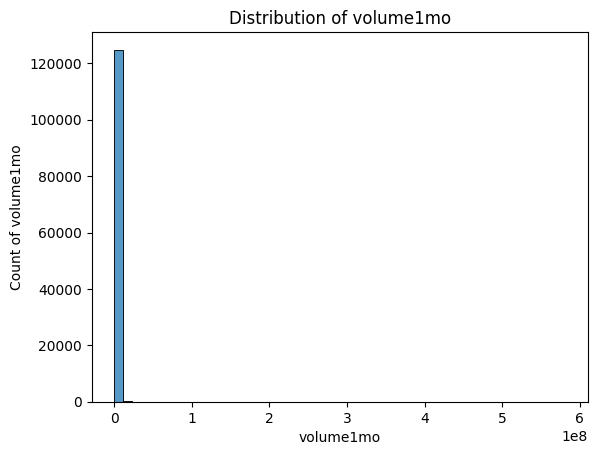

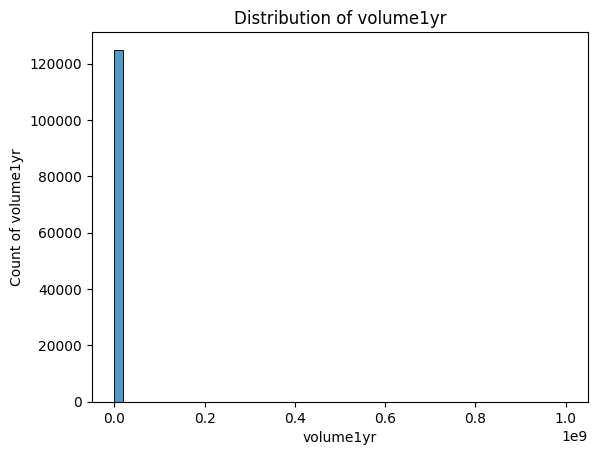

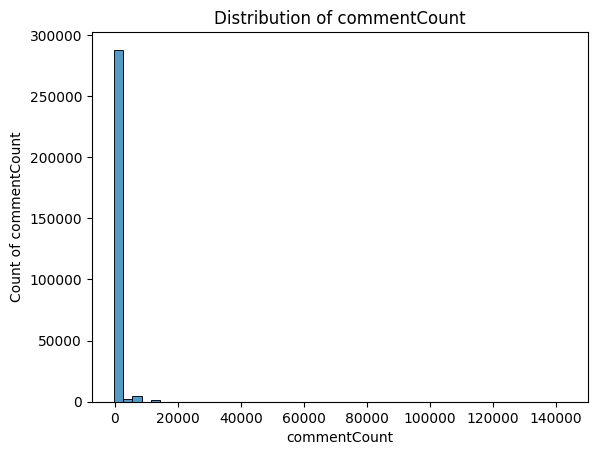

In [12]:
#Distribution graphs

for col in interesting_columns:
  plt.figure()
  sns.histplot(df[col].dropna(), bins=50)
  plt.title(f"Distribution of {col}")
  plt.xlabel(col)
  plt.ylabel(f"Count of {col}")
  plt.show

In [13]:
#Top Events

top_events = df.sort_values(by = "volume", ascending=False).head(15)
top_events[["title", "volume", "liquidity", "openInterest"]]

,title,volume,liquidity,openInterest
296905,Presidential Election Winner 2024,3.686335e+09,NaN,0.000000e+00
5259,NBA Champion,1.712133e+09,NaN,0.000000e+00
4089,Super Bowl Champion 2025,1.152274e+09,NaN,NaN
5053,Champions League Winner,1.001677e+09,NaN,0.000000e+00
21898,Democratic Presidential Nominee 2028,9.127318e+08,4.444742e+07,9.292797e+06
4970,Premier League Winner,8.086656e+08,NaN,0.000000e+00
15326,Big Game Champion 2026,7.040968e+08,NaN,0.000000e+00
36179,Fed decision in January?,6.594995e+08,NaN,0.000000e+00
296924,Popular Vote Winner 2024,6.281635e+08,NaN,0.000000e+00
26615,Who will Trump nominate as Fed Chair?,6.173337e+08,5.419848e+03,NaN


In [ ]:
#Sports vs Non-Sports
#t-test

#sports_vol = df[df[]]
